<a href="https://colab.research.google.com/github/rgopereira/OAC/blob/main/Prova1_OAC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Questão 1 – Sobre **INSTRUCTION SET ARCHITECTURE – ISA**, identifique a palavra correta e/ou preencha a lacuna (1.0 ponto) (0.SeisElementosDefinitorios)

In [1]:
# @title
import ipywidgets as widgets
from IPython.display import display

questoes = [
    (1, "Uma arquitetura é uma ______ de um (ou de uma classe de) processador(es).",
     ["materialização", "abstração"], "abstração"),
    (2, "Dominar uma ISA significa saber ______ o processador que a ISA descreve (em linguagem de montagem).",
     ["programar", "desligar"], "programar"),
    (3, "Podemos ter dezenas (ou centenas) de organizações diferentes que usam a ______ ARM v8.",
     ["organização", "arquitetura"], "arquitetura"),
    (5, "O processador repete, infinitamente: (1) ___ instrução → (2) ___ → (3) ___.",
     ["busca | decodifica | executa", "salva | identifica | salva"],
     "busca | decodifica | executa"),
]

respostas = []
for num, enunciado, opcoes, gabarito in questoes:
    print(f"({num}) {enunciado}")
    rb = widgets.RadioButtons(options=opcoes)
    respostas.append((num, rb, gabarito))
    display(rb)

print("(4) 'add $t3, $t3, $t4' é um exemplo de instrução de uma ISA. Escreva OUTRO exemplo:")
q4 = widgets.Text(placeholder="ex.: sub $t5, $t6, $t7")
display(q4)

botao = widgets.Button(description="Corrigir", button_style="success")
saida = widgets.Output()
display(botao, saida)

INSTRUCOES = ("sub", "addi", "lw", "sw", "beq", "bne", "j", "jr",
              "jal", "andi", "ori", "sll", "srl", "lui")

def corrigir(_):
    nota = 0.0
    with saida:
        saida.clear_output()
        for num, rb, gabarito in respostas:
            ok = rb.value == gabarito
            nota += 0.2 if ok else 0.0
            print(f"({num}) {'✅ Correto' if ok else '❌ Errado — gabarito: ' + gabarito}")
        partes = q4.value.strip().lower().split()
        ok4 = bool(partes) and partes[0] in INSTRUCOES
        nota += 0.2 if ok4 else 0.0
        print(f"(4) {'✅ Correto' if ok4 else '❌ Use outra instrução da mesma ISA, ex.: sub $t5, $t6, $t7'}")
        print(f"\nNota: {nota:.1f} / 1.0")

botao.on_click(corrigir)

(1) Uma arquitetura é uma ______ de um (ou de uma classe de) processador(es).


RadioButtons(options=('materialização', 'abstração'), value='materialização')

(2) Dominar uma ISA significa saber ______ o processador que a ISA descreve (em linguagem de montagem).


RadioButtons(options=('programar', 'desligar'), value='programar')

(3) Podemos ter dezenas (ou centenas) de organizações diferentes que usam a ______ ARM v8.


...

RadioButtons(options=('busca | decodifica | executa', 'salva | identifica | salva'), value='busca | decodifica…

(4) 'add $t3, $t3, $t4' é um exemplo de instrução de uma ISA. Escreva OUTRO exemplo:


Text(value='', placeholder='ex.: sub $t5, $t6, $t7')

Button(button_style='success', description='Corrigir', style=ButtonStyle())

Output()

Questão 2 – Sobre a diferença entre organização e arquitetura de processadores.

In [2]:
# @title
import re, unicodedata
import ipywidgets as widgets
from IPython.display import display

area = widgets.Textarea(
    placeholder="Escreva aqui sua resposta sobre a diferença entre arquitetura e organização...",
    layout=widgets.Layout(width="100%", height="180px"))
botao2 = widgets.Button(description="Analisar minha resposta", button_style="success")
out2 = widgets.Output()
display(area, botao2, out2)

def norm(s):
    s = unicodedata.normalize("NFD", s.lower())
    return s.encode("ascii", "ignore").decode()  # tira acentos: "interrupção" -> "interrupcao"

# (conceito esperado, padrões que evidenciam o sentido, mín. de padrões exigidos)
CONCEITOS = [
    ("Arquitetura = contrato lógico visível ao software/programador",
     [r"contrato", r"visivel ao (programador|software)"], 1),
    ("Citou elementos da arquitetura (ISA, endereçamento, dados, interrupções, exceções)",
     [r"\bisa\b", r"instruction set", r"enderecamento", r"tipos? de dados?",
      r"interrup", r"excec"], 2),
    ("Organização = implementação física (hardware, barramentos, ULA)",
     [r"barramento", r"\bula\b", r"implementacao fisica", r"hardware", r"circuito"], 1),
    ("Mesma arquitetura admite várias organizações",
     [r"mesma arquitetura", r"mesma isa", r"(varias|diversas|multiplas) organiza"], 1),
    ("Evolução de desempenho sem quebrar programas (compatibilidade)",
     [r"sem quebrar", r"nao quebra", r"compatib", r"evolu", r"mesmo programa"], 1),
]

def analisar(_):
    with out2:
        out2.clear_output()
        texto = norm(area.value)
        if len(texto.split()) < 25:
            print("⚠️ Texto muito curto — desenvolva melhor a comparação.")
            return
        nota = 0.0
        for conceito, padroes, minimo in CONCEITOS:
            hits = sum(1 for p in padroes if re.search(p, texto))
            ok = hits >= minimo
            nota += 0.2 if ok else 0.0
            print(f"{'✅' if ok else '❌'} {conceito}")
        print(f"\nAutoavaliação: {nota:.1f}/1.0 — a correção final do sentido é feita pelo professor.")

botao2.on_click(analisar)

Textarea(value='', layout=Layout(height='180px', width='100%'), placeholder='Escreva aqui sua resposta sobre a…

Button(button_style='success', description='Analisar minha resposta', style=ButtonStyle())

Output()

Questão 3 – Em (1) Leia o código fonte. A seguir complete a figura abaixo de (2) até (5).
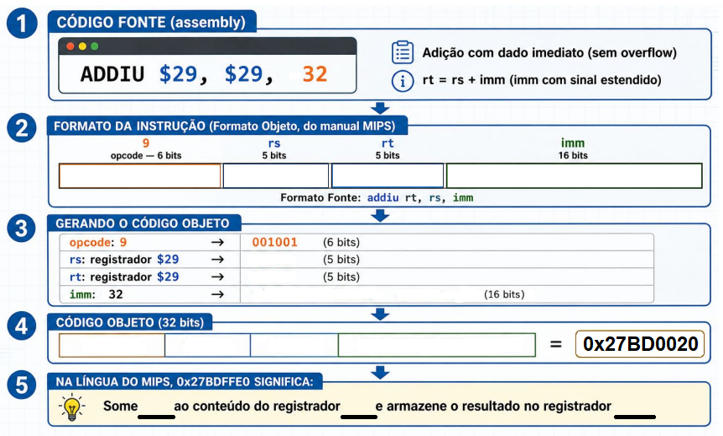

In [3]:
# @title
import ipywidgets as widgets
from IPython.display import display

print("(1) Código fonte: ADDIU $29, $29, 32\n")
print("Complete os campos do formato I:")

campos = {
    "opcode de addiu (6 bits)": widgets.Text(placeholder="6 bits"),
    "rs = $29 (5 bits)":        widgets.Text(placeholder="5 bits"),
    "rt = $29 (5 bits)":        widgets.Text(placeholder="5 bits"),
    "imm = 32 (16 bits)":       widgets.Text(placeholder="16 bits"),
}
GABARITO = {
    "opcode de addiu (6 bits)": "001001",
    "rs = $29 (5 bits)":        "11101",
    "rt = $29 (5 bits)":        "11101",
    "imm = 32 (16 bits)":       "0000000000100000",
}
for rotulo, w in campos.items():
    print(f"\n{rotulo}")
    display(w)

botao = widgets.Button(description="Montar código objeto", button_style="success")
out = widgets.Output()
display(botao, out)

def montar(_):
    with out:
        out.clear_output()
        ok_tudo = True
        for rotulo, w in campos.items():
            v = w.value.strip().replace(" ", "")
            ok = v == GABARITO[rotulo]
            ok_tudo &= ok
            print(f"{'✅' if ok else '❌'} {rotulo}: {v or '(vazio)'}")
        if not ok_tudo:
            print("\nCorrija os campos e tente de novo.")
            return
        bits = "".join(GABARITO[r] for r in campos)
        hexa = f"0x{int(bits, 2):08X}"
        print(f"\n(4) Código objeto: {bits} = {hexa}", "✅" if hexa == "0x27BD0020" else "")

botao.on_click(montar)

(1) Código fonte: ADDIU $29, $29, 32

Complete os campos do formato I:

opcode de addiu (6 bits)


Text(value='', placeholder='6 bits')


rs = $29 (5 bits)


Text(value='', placeholder='5 bits')


rt = $29 (5 bits)


Text(value='', placeholder='5 bits')


imm = 32 (16 bits)


Text(value='', placeholder='16 bits')

Button(button_style='success', description='Montar código objeto', style=ButtonStyle())

Output()

Questão 4 – Atribua Verdadeiro (V) ou Falso (F) para as afirmações a seguir. Caso Falso, corrija abaixo.

In [4]:
# @title
import ipywidgets as widgets
from IPython.display import display

MODOS = [
    ("Modo Imediato", "o operando é uma constante contida dentro do código da instrução, "
     "estando assim imediatamente disponível para uso, o que justifica o nome do modo"),
    ("Modo a Registrador", "o operando é uma referência a (i.e. um endereço de) um registrador "
     "interno do processador"),
    ("Modo Direto ou Absoluto", "o operando é uma referência a (i.e. um endereço de) uma posição "
     "da memória externa ao processador"),
    ("Modo Relativo", "o operando é um valor a ser adicionado a um registrador existente para "
     "obter o endereço de um operando (no exemplo do MIPS, o modo relativo é relativo ao valor "
     "do registrador Program Counter, PC, do MIPS)"),
    ("Modo Indireto", "o operando é o endereço do endereço de um dado (muito útil para manipular "
     "vetores e matrizes em linguagem de montagem)"),
    ("Modo Base-Deslocamento", "usa-se aqui dois valores para permitir localizar o operando: o "
     "primeiro é um endereço base (em um registrador ou em uma posição de memória), o segundo é "
     "uma constante a ser somada com o endereço base para obter o endereço do operando da instrução"),
]

GABARITO = {
    "Modo Imediato":           ("V", []),
    "Modo a Registrador":      ("V", []),
    "Modo Direto ou Absoluto": ("V", []),
    "Modo Relativo":           ("V", []),
    "Modo Indireto":           ("V", []),
    "Modo Base-Deslocamento":  ("V", []),
}

respostas = []
for nome, definicao in MODOS:
    print(f"(   ) {nome} — {definicao}\n")
    vf = widgets.ToggleButtons(options=["V", "F"], description="Resposta:")
    corr = widgets.Textarea(placeholder="Caso F, corrija a afirmação aqui...",
                            layout=widgets.Layout(width="95%", height="55px"))
    respostas.append((nome, vf, corr))
    display(vf, corr)   # ← LINHA QUE FALTAVA: exibe o seletor e o campo de correção

botao = widgets.Button(description="Corrigir", button_style="success")
out = widgets.Output()
display(botao, out)

def corrigir(_):
    with out:
        out.clear_output()
        nota, valor = 0.0, 1.0 / len(respostas)
        for nome, vf, corr in respostas:
            esperado, palavras = GABARITO[nome]
            if vf.value is None:
                print(f"⚠️ {nome}: sem resposta")
                continue
            if esperado == "V":
                ok = vf.value == "V"
                feedback = "" if ok else "afirmação verdadeira como está"
            else:  # variação com afirmação falsa: exige F + correção com palavra-chave
                texto = corr.value.lower()
                ok = vf.value == "F" and any(p in texto for p in palavras)
                feedback = "" if ok else f"gabarito: F — corrija mencionando: {', '.join(palavras)}"
            nota += valor if ok else 0.0
            print(f"{'✅' if ok else '❌'} {nome} {('| ' + feedback) if feedback else ''}")
            if not ok and corr.value.strip():
                print(f"   Sua correção foi registrada para revisão: “{corr.value.strip()}”")
        print(f"\nNota: {nota:.2f} / 1.0")

botao.on_click(corrigir)

(   ) Modo Imediato — o operando é uma constante contida dentro do código da instrução, estando assim imediatamente disponível para uso, o que justifica o nome do modo



ToggleButtons(description='Resposta:', options=('V', 'F'), value='V')

Textarea(value='', layout=Layout(height='55px', width='95%'), placeholder='Caso F, corrija a afirmação aqui...…

(   ) Modo a Registrador — o operando é uma referência a (i.e. um endereço de) um registrador interno do processador



ToggleButtons(description='Resposta:', options=('V', 'F'), value='V')

...

(   ) Modo Base-Deslocamento — usa-se aqui dois valores para permitir localizar o operando: o primeiro é um endereço base (em um registrador ou em uma posição de memória), o segundo é uma constante a ser somada com o endereço base para obter o endereço do operando da instrução



ToggleButtons(description='Resposta:', options=('V', 'F'), value='V')

Textarea(value='', layout=Layout(height='55px', width='95%'), placeholder='Caso F, corrija a afirmação aqui...…

Button(button_style='success', description='Corrigir', style=ButtonStyle())

Output()

In [5]:
# @title
import ipywidgets as widgets
from IPython.display import display

print("Questão 5 — Sobre o processador escolhido no trabalho. Discorra sobre três aspectos relevantes levantados na sua pesquisa:\n")

resposta = widgets.Textarea(
    placeholder="Aspecto 1: ...\n\nAspecto 2: ...\n\nAspecto 3: ...",
    layout=widgets.Layout(width="100%", height="280px"))
display(resposta)

contador = widgets.Label()
def atualiza(_):
    n = len(resposta.value.split())
    contador.value = f"Palavras: {n}" + (" — desenvolva mais." if n < 60 else " ✔")
resposta.observe(atualiza, names="value")
display(contador)

salvar = widgets.Button(description="Salvar resposta (.txt)", button_style="primary")
out = widgets.Output()
display(salvar, out)

def salvar_resposta(_):
    with out:
        out.clear_output()
        if not resposta.value.strip():
            print("⚠️ Escreva a resposta antes de salvar.")
            return
        nome = "questao5_resposta.txt"
        with open(nome, "w", encoding="utf-8") as f:
            f.write("Questão 5 — Processador escolhido no trabalho\n\n")
            f.write(resposta.value)
        try:
            from google.colab import files
            files.download(nome)          # Colab: baixa o arquivo direto
        except ImportError:
            pass                          # Jupyter local: arquivo fica na pasta do notebook
        print(f"✅ Resposta salva em {nome}.")

salvar.on_click(salvar_resposta)

Questão 5 — Sobre o processador escolhido no trabalho. Discorra sobre três aspectos relevantes levantados na sua pesquisa:



Textarea(value='', layout=Layout(height='280px', width='100%'), placeholder='Aspecto 1: ...\n\nAspecto 2: ...\…

Label(value='')

Button(button_style='primary', description='Salvar resposta (.txt)', style=ButtonStyle())

Output()

Questão 6 – Considerando que um processador precisa escrever e ler dados. A memória contém os valores: A = 5 (endereço 0), B = 3 (endereço 4), C = 10 (endereço 8). O registrador $s0 possui o valor 0x00000000. Execute o código abaixo passo a passo e diga o valor final armazenado em cada registrador e na memória após toda a execução do programa:

**$s0 = 0x00000000**

**lw   $t0,  0($s0)**

**lw   $t1,  4($s0)**

**sub  $t2, $t0, $t1**

**sw   $t2, 12($s0)**

**lw   $t3,  8($s0)**

**sub  $t4, $t3, $t2**

**sw   $t4, 16($s0)**


In [6]:
# @title
import ipywidgets as widgets
from IPython.display import display

OPCOES = ["?"] + list(range(16))   # 0 a 15, com "?" = sem resposta

GABARITO = {
    "$t0": 5, "$t1": 3, "$t2": 2, "$t3": 10, "$t4": 8,
    "mem[0]": 5, "mem[4]": 3, "mem[8]": 10, "mem[12]": 2, "mem[16]": 8,
}

selecoes = {}

# REGISTRADORES na horizontal
print("REGISTRADORES:")
linha_regs = []
for r in ["$t0", "$t1", "$t2", "$t3", "$t4"]:
    w = widgets.Dropdown(options=OPCOES, description=r,
                         layout=widgets.Layout(width="auto", flex="1 1 0"),
                         style={"description_width": "initial"})
    selecoes[r] = w
    linha_regs.append(w)
display(widgets.HBox(linha_regs,
        layout=widgets.Layout(display="flex", flex_flow="row wrap", width="100%")))

# MEMÓRIA na horizontal
print("\nMEMÓRIA:")
linha_mem = []
for m in ["mem[0]", "mem[4]", "mem[8]", "mem[12]", "mem[16]"]:
    w = widgets.Dropdown(options=OPCOES, description=m,
                         layout=widgets.Layout(width="auto", flex="1 1 0"),
                         style={"description_width": "initial"})
    selecoes[m] = w
    linha_mem.append(w)
display(widgets.HBox(linha_mem,
        layout=widgets.Layout(display="flex", flex_flow="row wrap", width="100%")))

botao = widgets.Button(description="Corrigir", button_style="success")
out = widgets.Output()
display(botao, out)

def corrigir(_):
    with out:
        out.clear_output()
        acertos = 0
        for nome, gab in GABARITO.items():
            v = selecoes[nome].value
            if v == "?":
                print(f"⚠️ {nome}: sem resposta")
                continue
            ok = v == gab
            acertos += ok
            print(f"{'✅' if ok else '❌'} {nome} = {v} (gabarito: {gab})")
        print(f"\nAcertos: {acertos}/{len(GABARITO)}")

botao.on_click(corrigir)

REGISTRADORES:



MEMÓRIA:


Button(button_style='success', description='Corrigir', style=ButtonStyle())

Output()

In [7]:
# @title
# Apoio: execute depois de responder para conferir o raciocínio
mem = {0: 5, 4: 3, 8: 10, 12: 0, 16: 0}
reg = {"$t0": 0, "$t1": 0, "$t2": 0, "$t3": 0, "$t4": 0}
S0 = 0  # $s0 = 0x00000000

def passo(instr):
    p = instr.replace(",", "").split()
    op, rd = p[0], p[1]
    if op == "lw":
        end = S0 + int(p[2].split("(")[0])
        reg[rd] = mem[end]
        print(f"   {rd} ← mem[{end}] = {mem[end]}")
    elif op == "sw":
        end = S0 + int(p[2].split("(")[0])
        mem[end] = reg[rd]
        print(f"   mem[{end}] ← {rd} = {reg[rd]}")
    elif op == "sub":
        reg[rd] = reg[p[2]] - reg[p[3]]
        print(f"   {rd} ← {p[2]} - {p[3]} = {reg[rd]}")

for instr in ["lw  $t0,  0($s0)", "lw  $t1,  4($s0)", "sub $t2, $t0, $t1",
              "sw  $t2, 12($s0)", "lw  $t3,  8($s0)", "sub $t4, $t3, $t2",
              "sw  $t4, 16($s0)"]:
    print(f"> {instr}")
    passo(instr)

print("\nEstado final:")
print("REGISTRADORES:", reg)
print("MEMÓRIA:", {f"mem[{k}]": v for k, v in sorted(mem.items())})

> lw  $t0,  0($s0)
   $t0 ← mem[0] = 5
> lw  $t1,  4($s0)
   $t1 ← mem[4] = 3
> sub $t2, $t0, $t1
   $t2 ← $t0 - $t1 = 2
> sw  $t2, 12($s0)
   mem[12] ← $t2 = 2
> lw  $t3,  8($s0)
   $t3 ← mem[8] = 10
> sub $t4, $t3, $t2
   $t4 ← $t3 - $t2 = 8
> sw  $t4, 16($s0)
   mem[16] ← $t4 = 8

Estado final:
REGISTRADORES: {'$t0': 5, '$t1': 3, '$t2': 2, '$t3': 10, '$t4': 8}
MEMÓRIA: {'mem[0]': 5, 'mem[4]': 3, 'mem[8]': 10, 'mem[12]': 2, 'mem[16]': 8}


Questão 7 – Sobre instruções lógicas. Escreva a sequência que inverte a ordem dos 4 bytes, **resultando em 0x33441122.** Você deve usar sll, srl, andi e or. Considere **$t0 = 0x11223344**.

In [8]:
# @title
import ipywidgets as widgets
import re
from IPython.display import display

ALVO = 0x33441122                      # ← fonte única do gabarito
PERMITIDAS = {"sll", "srl", "andi", "or"}

print("Questão 7 — Instruções lógicas")
print(f"Considere $t0 = 0x11223344. Escreva a sequência que resulta em $t0 = {ALVO:#010x}.")
print(f"Use apenas: {', '.join(sorted(PERMITIDAS))}  |  uma instrução por linha\n")

area = widgets.Textarea(
    placeholder="Escreva aqui sua sequência de instruções…",
    layout=widgets.Layout(width="100%", height="200px"))
botao = widgets.Button(description="Executar e avaliar", button_style="success")
out = widgets.Output()
display(area, botao, out)

def reg_nome(tok):
    t = tok.strip().lower()
    if t in ("$zero", "zero"): return "zero"
    if re.fullmatch(r"\$(t[0-9]|s[0-7]|a[0-3]|v[0-1]|ra|sp|gp|fp)", t): return t[1:]
    return None

def interpreta(linhas):
    regs = {"t0": 0x11223344}
    usadas = set()
    for i, lin in enumerate(linhas, 1):
        lin = re.sub(r"#.*", "", lin).replace(",", " ").split()
        if not lin: continue
        op = lin[0].lower()
        if op not in PERMITIDAS:
            raise ValueError(f"linha {i}: '{lin[0]}' não é permitida (use sll, srl, andi ou or)")
        if len(lin) != 4:
            raise ValueError(f"linha {i}: formato esperado 'op rd, rs, valor'")
        rd, rs = reg_nome(lin[1]), reg_nome(lin[2])
        if rd is None or rs is None:
            raise ValueError(f"linha {i}: registrador inválido em '{' '.join(lin)}'")
        usadas.add(op)
        if op in ("sll", "srl"):
            sh = int(lin[3], 0)
            if not (0 <= sh <= 31):
                raise ValueError(f"linha {i}: deslocamento inválido ({sh})")
            a = regs.get(rs, 0)
            regs[rd] = (a << sh) & 0xFFFFFFFF if op == "sll" else a >> sh
        elif op == "andi":
            imm = int(lin[3], 0)
            if not (0 <= imm <= 0xFFFF):
                raise ValueError(f"linha {i}: imediato andi deve estar entre 0 e 0xFFFF")
            regs[rd] = regs.get(rs, 0) & imm
        else:  # or
            rt = reg_nome(lin[3])
            if rt is None:
                raise ValueError(f"linha {i}: terceiro operando de 'or' deve ser registrador")
            regs[rd] = regs.get(rs, 0) | regs.get(rt, 0)
    return regs, usadas

def avaliar(_):
    with out:
        out.clear_output()
        try:
            regs, usadas = interpreta(area.value.splitlines())
        except ValueError as e:
            print(f"❌ {e}")
            return
        faltam = PERMITIDAS - usadas
        ok_ops = not faltam
        final = regs.get("t0", 0)
        ok_alvo = final == ALVO
        print(f"{'✅' if ok_ops else '❌'} Instruções usadas: "
              f"{', '.join(sorted(usadas)) or '(nenhuma)'}"
              + (f"  |  faltam: {', '.join(sorted(faltam))}" if faltam else ""))
        # rótulo derivado de ALVO — nunca mais divergente da comparação
        print(f"{'✅' if ok_alvo else '❌'} $t0 final = {final:#010x}  |  alvo = {ALVO:#010x}")
        if ok_ops and ok_alvo:
            print("\n🎯 Resposta correta!")
        elif ok_alvo:
            print("\n🟡 Resultado certo, mas faltou usar todas as instruções exigidas.")
        else:
            print("\n❌ A sequência não produz o alvo — revise a lógica.")

botao.on_click(avaliar)

Questão 7 — Instruções lógicas
Considere $t0 = 0x11223344. Escreva a sequência que resulta em $t0 = 0x33441122.
Use apenas: andi, or, sll, srl  |  uma instrução por linha



Textarea(value='', layout=Layout(height='200px', width='100%'), placeholder='Escreva aqui sua sequência de ins…

Button(button_style='success', description='Executar e avaliar', style=ButtonStyle())

Output()

In [9]:
# @title
import ipywidgets as widgets
from IPython.display import display

gab = widgets.Button(description="Revelar gabarito", button_style="warning")
out_g = widgets.Output()
display(gab, out_g)

def revelar(_):
    with out_g:
        out_g.clear_output()
        print("andi $t1, $t0, 0x0000FFFF   # isola a metade baixa: $t1 = 0x00003344")
        print("srl  $t2, $t0, 16       # metade alta desce:    $t2 = 0x00001122")
        print("sll  $t1, $t1, 16       # metade baixa sobe:    $t1 = 0x33440000")
        print("or   $t0, $t1, $t2      # 0x33440000 | 0x00001122 = 0x33441122 ✓")

gab.on_click(revelar)

Button(button_style='warning', description='Revelar gabarito', style=ButtonStyle())

Output()

Para a questão a seguir instale o MARS 4.5

In [12]:
# @title
import os, subprocess

if not os.path.exists("Mars4_5.jar"):
    !wget -q https://dpetersanderson.github.io/Mars4_5.jar -O Mars4_5.jar

print("MARS baixado:", os.path.getsize("Mars4_5.jar"), "bytes")
# O Colab já traz OpenJDK. Se o comando abaixo falhar, descomente a linha do apt:
# !apt-get -qq update && apt-get -qq install -y default-jre-headless
print(subprocess.run(["java", "-version"], capture_output=True, text=True).stderr.strip())

MARS baixado: 4169142 bytes
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)


Questão 8 – Codifique um programa em Assembly MIPS que **some os inteiros de 1 até N e armazene o resultado na memória**. Considere **N = 5**. Use **$t0, $t1, $t2**.

In [13]:
# @title
import ipywidgets as widgets, subprocess, pathlib
from IPython.display import display

editor = widgets.Textarea(
    value=".data\nsoma: .word 0\n\n.text\nmain:\n    # escreva seu programa aqui\n",
    layout=widgets.Layout(width="100%", height="260px", font_family="monospace"))
botao = widgets.Button(description="Montar e executar no MARS", button_style="success")
out = widgets.Output()
display(editor, botao, out)

def rodar(_):
    with out:
        out.clear_output()
        pathlib.Path("q8.asm").write_text(editor.value, encoding="utf-8")
        if pathlib.Path("mem.txt").exists():
            pathlib.Path("mem.txt").unlink()

        # nc = sem aviso de copyright | me = mensagens do MARS no stderr
        # dump = despeja a memória de dados após a execução
        cmd = ["java", "-jar", "Mars4_5.jar", "nc", "me",
               "dump", "0x10010000-0x10010010", "HexText", "mem.txt", "q8.asm"]
        r = subprocess.run(cmd, capture_output=True, text=True)

        if r.stderr.strip():
            print("MARS:\n" + r.stderr.strip() + "\n")
        if r.stdout.strip():
            print("Saída do programa:\n" + r.stdout.strip() + "\n")

        if not pathlib.Path("mem.txt").exists():
            print("⚠️ Nada foi gravado na memória — verifique o 'sw' e o rótulo 'soma'.")
            return

        palavras = pathlib.Path("mem.txt").read_text().split()
        print("Memória a partir de 0x10010000:")
        for i, w in enumerate(palavras):
            print(f"  mem[0x{0x10010000 + 4*i:08X}] = 0x{w}  ({int(w, 16)})")

        if palavras and int(palavras[0], 16) == 15:
            print("\n✅ mem[0x10010000] = 15 — soma de 1 a 5 correta!")
        else:
            print("\n❌ Esperado 15 na primeira palavra da memória.")

botao.on_click(rodar)

Textarea(value='.data\nsoma: .word 0\n\n.text\nmain:\n    # escreva seu programa aqui\n', layout=Layout(height…

Button(button_style='success', description='Montar e executar no MARS', style=ButtonStyle())

Output()

In [15]:
# @title
import ipywidgets as widgets
from IPython.display import display

gab = widgets.Button(description="Revelar gabarito", button_style="warning")
out_g = widgets.Output()
display(gab, out_g)

def revelar(_):
    with out_g:
        out_g.clear_output()
        print(".text")
        print("main:")
        print("addi $t0, $zero, 5      # $t0 = N = 5")
        print("addi $t1, $zero, 0      # $t1 = soma = 0")
        print("addi $t2, $zero, 1      # $t2 = i = 1")
        print("loop:")
        print("add  $t1, $t1, $t2      # soma += i")
        print("addi $t2, $t2, 1        # i++")
        print("ble  $t2, $t0, loop     # repete enquanto i <= N")
        print("sw   $t1, soma          # armazena o resultado na memória")
        print("move $a0, $t1           # $a0 = soma (corrigido)")
        print("li   $v0, 1             # syscall: imprimir inteiro")
        print("syscall")
        print("li   $v0, 10            # syscall: sair")
        print("syscall")
gab.on_click(revelar)

Button(button_style='warning', description='Revelar gabarito', style=ButtonStyle())

Output()

**Questão 9** – Quando uma função precisa usar registradores que já pertencem a quem a chamou (como **\$s0** ou **\$ra**) - é necessário salvá-los na pilha antes de modificar e restaurá-los antes de retornar. Com base nessa informação - preencha os valores necessário para a operação de dois registradores na pilha (**\$s0**ou **\$ra**)

In [16]:
# @title
import ipywidgets as widgets
from IPython.display import display

print("""    .text
main:
    # 1. Aloca espaço na pilha para 2 registradores (8 bytes -> 4 bytes por palavra)
    subi $sp, $sp, [A]
    # 2. Salva os registradores que serão modificados
    sw   $ra, [B]($sp)       # endereço de retorno
    sw   $s0, [C]($sp)       # registrador $s0
    #  Corpo da função
    addi $s0, $zero, 10
    # 2.1 Restaura os registradores da pilha
    lw   $s0, [D]($sp)
    lw   $ra, [E]($sp)
    # 3. Libera o espaço da pilha
    addi $sp, $sp, [F]
    # 4. Retorna
    jr   $ra
""")

OPCOES = ["?"] + [0, 4, 8, 12, 16]

campos = {
    "A": ("subi $sp, $sp,", 8),
    "B": ("sw $ra,  _($sp)", 4),
    "C": ("sw $s0,  _($sp)", 0),
    "D": ("lw $s0,  _($sp)", 0),
    "E": ("lw $ra,  _($sp)", 4),
    "F": ("addi $sp, $sp,", 8),
}

seletores = {}
linha = []
for chave, (rotulo, _) in campos.items():
    w = widgets.Dropdown(options=OPCOES, description=f"[{chave}] {rotulo}",
                         layout=widgets.Layout(width="auto", flex="1 1 0"),
                         style={"description_width": "initial"})
    seletores[chave] = w
    linha.append(w)

display(widgets.HBox(linha,
        layout=widgets.Layout(display="flex", flex_flow="row wrap", width="100%")))

botao = widgets.Button(description="Corrigir", button_style="success")
out = widgets.Output()
display(botao, out)

def corrigir(_):
    with out:
        out.clear_output()
        vals = {k: seletores[k].value for k in campos}
        if any(v == "?" for v in vals.values()):
            print("⚠️ Preencha todos os campos (A a F).")
            return

        # Verificação lógica: alocação/liberação de 8 bytes e offsets espelhados
        ok_alloc = vals["A"] == 8 and vals["F"] == 8
        # salvar e restaurar com offsets iguais, um em 0 e outro em 4
        ok_b_e = vals["B"] == vals["E"] and vals["B"] in (0, 4)
        ok_c_d = vals["C"] == vals["D"] and vals["C"] in (0, 4)
        ok_dist = vals["B"] != vals["C"]

        para = {
            "A (alocar 8 bytes)": (ok_alloc, vals["A"]),
            "B/E ($ra espelhado)": (ok_b_e, f"{vals['B']}/{vals['E']}"),
            "C/D ($s0 espelhado)": (ok_c_d, f"{vals['C']}/{vals['D']}"),
            "B e C distintos": (ok_dist, f"{vals['B']} e {vals['C']}"),
        }
        acertos = 0
        for nome, (ok, v) in para.items():
            acertos += ok
            print(f"{'✅' if ok else '❌'} {nome}: {v}")

        print(f"\nNota: {acertos/4 * 2.0:.2f} / 2.0")
        if acertos == 4:
            print("\n🎯 Correto! $ra em 4($sp), $s0 em 0($sp), pilha alocada e liberada em 8.")

botao.on_click(corrigir)

    .text
main:
    # 1. Aloca espaço na pilha para 2 registradores (8 bytes -> 4 bytes por palavra)
    subi $sp, $sp, [A]
    # 2. Salva os registradores que serão modificados
    sw   $ra, [B]($sp)       # endereço de retorno
    sw   $s0, [C]($sp)       # registrador $s0
    #  Corpo da função
    addi $s0, $zero, 10
    # 2.1 Restaura os registradores da pilha
    lw   $s0, [D]($sp)
    lw   $ra, [E]($sp)
    # 3. Libera o espaço da pilha
    addi $sp, $sp, [F]
    # 4. Retorna
    jr   $ra



Button(button_style='success', description='Corrigir', style=ButtonStyle())

Output()

Questão 10 – Observe o Procedimento Folha a seguir. Responda as questões a seguir:

In [17]:
# @title
import ipywidgets as widgets
import html
import unicodedata
from IPython.display import display

CODIGO_1 = """    .data
msg_a:    .asciiz "Primeiro numero: "
msg_b:    .asciiz "Segundo numero: "
msg_res:  .asciiz "Maior valor: "
    .text
              .globl main
main:
    li    $t0, 4
    li    $t1, 5
    move  $a0, $t0
    move  $a1, $t1
    jal   maximo
    move  $s2, $v0
    li    $v0, 10"""

CODIGO_2 = """    .text
.globl maximo
maximo:
    slt   $t0, $a1, $a0
    beq   $t0, $zero, else
    add   $v0, $a0, $zero
    j     fim
else:
    add   $v0, $a1, $zero
fim:
    jr    $ra"""

def painel(titulo, codigo):
    corpo = html.escape(codigo).replace("\n", "<br>")
    return widgets.HTML(
        f"<div style='border:1px solid #ccc;border-radius:6px;padding:10px;"
        f"background:#f8f9fa;margin:4px;'>"
        f"<b style='font-family:monospace;'>{titulo}</b>"
        f"<pre style='font-family:monospace;font-size:12px;line-height:1.35;"
        f"white-space:pre;overflow:auto;'>{corpo}</pre></div>",
        layout=widgets.Layout(width="50%", min_width="320px"))

display(widgets.HBox(
    [painel("CÓDIGO 1", CODIGO_1), painel("CÓDIGO 2", CODIGO_2)],
    layout=widgets.Layout(display="flex", flex_flow="row wrap", width="100%")))

print("\nResponda às questões abaixo:\n")

def norm(s):
    return unicodedata.normalize("NFD", s.lower()).encode("ascii", "ignore").decode()

q1 = widgets.Dropdown(
    options=["?", "1 caller e 1 callee", "2 callers e 1 callee",
             "1 caller e 2 callees", "2 callers e 2 callees"],
    description="Q1. CALLERS e CALLEES:", style={"description_width": "initial"})
q2 = widgets.Textarea(placeholder="Escreva sua resposta...",
                      layout=widgets.Layout(width="100%", height="70px"))
q3 = widgets.Textarea(placeholder="Escreva sua resposta...",
                      layout=widgets.Layout(width="100%", height="70px"))
q4a = widgets.Textarea(placeholder="Escreva sua resposta...",
                       layout=widgets.Layout(width="100%", height="55px"))
q4b = widgets.Textarea(placeholder="Escreva sua resposta...",
                       layout=widgets.Layout(width="100%", height="55px"))

print("Q2. O que faz o comando jal maximo?")
display(q2)
print("Q3. Qual a necessidade do comando slt $t0, $a1, $a0?")
display(q3)
print("Q4. Qual a função dos registradores:")
print("  a) $a0")
display(q4a)
print("  b) $ra")
display(q4b)

GAB_Q1 = "1 caller e 1 callee"
CHECKS = [
    ("Q2", [r"\bra\b", r"retorno", r"maximo"], 0.5),          # jal: salva $ra e pula para maximo
    ("Q3", [r"compar", r"maior|menor"], 0.5),                 # slt: compara $a1 com $a0
    ("Q4a", [r"argumento|parametro|primeiro"], 0.25),          # $a0: primeiro argumento
    ("Q4b", [r"retorno|endereco"], 0.25),                     # $ra: endereço de retorno (jal)
]

botao = widgets.Button(description="Corrigir", button_style="success")
out = widgets.Output()
display(botao, out)

def corrigir(_):
    with out:
        out.clear_output()
        total = 0.0

        if q1.value == "?":
            print("⚠️ Responda a Q1.")
        elif q1.value == GAB_Q1:
            total += 0.5
            print("✅ Q1 (0.5): 1 caller (main) e 1 callee (maximo).")
        else:
            print("❌ Q1 (0.0): gabarito 1 caller (main) e 1 callee (maximo).")

        textos = {"Q2": q2.value, "Q3": q3.value, "Q4a": q4a.value, "Q4b": q4b.value}
        import re
        for rotulo, padroes, peso in CHECKS:
            t = norm(textos[rotulo])
            if not t.strip():
                print(f"⚠️ {rotulo}: sem resposta.")
                continue
            achados = sum(1 for p in padroes if re.search(p, t))
            if achados == len(padroes):
                pts, total_pts = peso, peso
                print(f"✅ {rotulo} (+{peso:.2f}): resposta completa.")
            elif achados >= 1:
                pts, total_pts = peso / 2, peso
                print(f"🟡 {rotulo} (+{peso/2:.2f}): conceito parcial.")
            else:
                pts, total_pts = 0.0, peso
                print(f"❌ {rotulo} (0.0): não mencionou o conceito-chave.")
            total += pts

        print(f"\nNota: {total:.2f} / 2.0")

botao.on_click(corrigir)

gab = widgets.Button(description="Gabarito (professor)", button_style="warning")
out_g = widgets.Output()
display(gab, out_g)

def revelar(_):
    with out_g:
        out_g.clear_output()
        print("1 caller e 1 callee: quem chama é main; quem é chamado é maximo.")
        print("jal maximo: 'jump and link' — salva em $ra o endereço da instrução seguinte")
        print("  (PC+4) e desvia para o rótulo maximo.")
        print("slt $t0, $a1, $a0: $t0 = 1 se $a1 < $a0 (ou seja, se $a0 é o maior);")
        print("  o beq seguinte desvia para 'else' quando $t0 = 0 (a1 >= a0).")
        print("$a0: registrador de argumentos — recebe o 1º argumento da função ($t0).")
        print("$ra: registrador de endereço de retorno — preenchido pelo jal;")
        print("  o jr $ra usa esse endereço para voltar a quem chamou.")

gab.on_click(revelar)


Responda às questões abaixo:

Q2. O que faz o comando jal maximo?


Textarea(value='', layout=Layout(height='70px', width='100%'), placeholder='Escreva sua resposta...')

Q3. Qual a necessidade do comando slt $t0, $a1, $a0?


Textarea(value='', layout=Layout(height='70px', width='100%'), placeholder='Escreva sua resposta...')

Q4. Qual a função dos registradores:
  a) $a0


...

Textarea(value='', layout=Layout(height='55px', width='100%'), placeholder='Escreva sua resposta...')

Button(button_style='success', description='Corrigir', style=ButtonStyle())

Output()

Button(button_style='warning', description='Gabarito (professor)', style=ButtonStyle())

Output()